# Lab 09 - NLP
*Dataset Link:* https://huggingface.co/datasets/stanfordnlp/imdb

### Install Libraries

In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn wordcloud datasets

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from datasets import load_dataset
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

d:\anaconda\envs\torch_dml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load Dataset

In [2]:
dataset = load_dataset("stanfordnlp/imdb")

# Load the training and testing splits
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

print("\nFirst five training reviews:")
print(train_df.head())

Training dataset: (25000, 2)
Testing dataset: (25000, 2)

First five training reviews:
                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0


### Preprocess
- Convert text to lowercase
- Remove HTML tags
- Remove URLs
- Replace repeated whitespace with a single space
- Remove empyty reviews (if have)

In [3]:
def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Replace repeated whitespace with a single space
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Clean training and testing reviews
train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

# Remove any empty reviews if there is
train_df = train_df[train_df["clean_text"].str.len() > 0].copy()
test_df = test_df[test_df["clean_text"].str.len() > 0].copy()

### Word Cloud

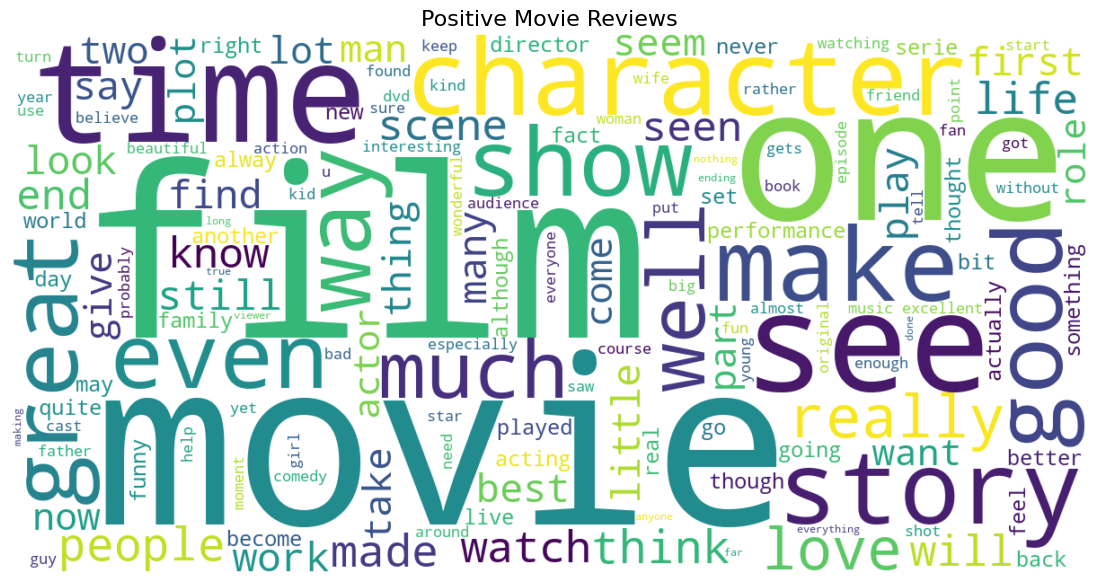

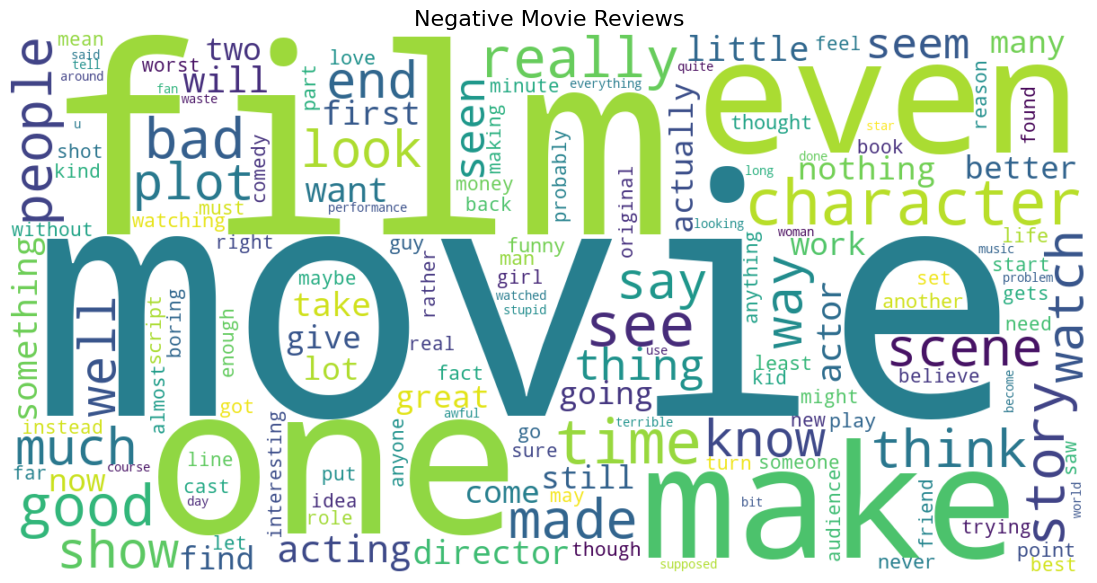

In [4]:
# Combine positive reviews
positive_text = " ".join(
    train_df.loc[
        train_df["label"] == 1,
        "clean_text"
    ]
)

# Combine negative reviews
negative_text = " ".join(
    train_df.loc[
        train_df["label"] == 0,
        "clean_text"
    ]
)

# Generate positive word cloud
positive_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=STOPWORDS,
    max_words=150
).generate(positive_text)

plt.figure(figsize=(14, 7))
plt.imshow(positive_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Movie Reviews", fontsize=16)
plt.show()


# Generate negative word cloud
negative_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=STOPWORDS,
    max_words=150
).generate(negative_text)

plt.figure(figsize=(14, 7))
plt.imshow(negative_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Movie Reviews", fontsize=16)
plt.show()

### Convert text into numerical features using TF-IDF
TF-IDF vectorizer:
- Limit the vocabulary to the 30,000 most useful features.
- Include individual words and two-word combinations.
- Ignore terms that occur in fewer than two training documents.
- Ignore terms appearing in more than 95% of training documents.

**Each row represents one review, and each column represents a word or two-word combination.**

The values indicate the TF-IDF weights of the corresponding features.

In [5]:
# Separate input features and target labels
X_train = train_df["clean_text"]
y_train = train_df["label"]

X_test = test_df["clean_text"]
y_test = test_df["label"]

# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Learn vocabulary and weights from training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the learned vocabulary
X_test_tfidf = tfidf.transform(X_test)


# Display feature dimensions
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("\nNumber of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (25000, 30000)
Testing TF-IDF shape: (25000, 30000)

Number of TF-IDF features: 30000


### Train Models
- Multinomial Naive Bayes
- Logistic Regression
- Linear SVM

In [6]:
# Define models
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000,random_state=42),
    "Linear SVM": LinearSVC(random_state=42)
}

# Train each model
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)

### Evaluate Models

In [7]:
results = []
predictions = {}


for model_name, model in models.items():

    # Predict sentiment for test reviews
    y_pred = model.predict(X_test_tfidf)

    # Store predictions for later analysis
    predictions[model_name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1-score (Macro)": f1
    })

    # Display detailed classification report
    print(f"Model: {model_name}")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Negative", "Positive"],
            zero_division=0
        )
    )


# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nModel Comparison")
print(results_df.round(4).to_string(index=False))

Model: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.86      0.88      0.87     12500
    Positive       0.88      0.86      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000

Model: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000

Model: Linear SVM
              precision    recall  f1-score   support

    Negative       0.89      0.90      0.89     12500
    Positive       0.90      0.89      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted a

### Compare Model accuracy

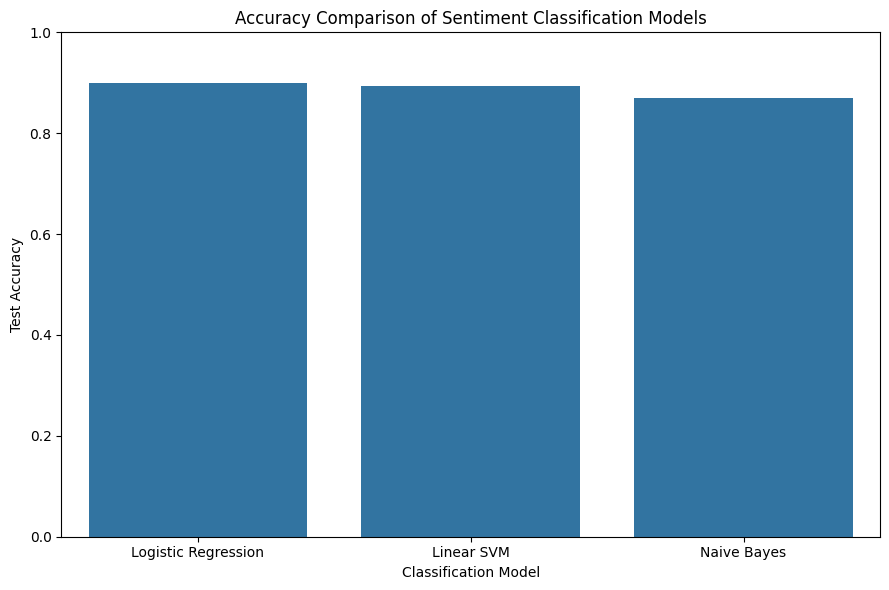

In [8]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Sentiment Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Confusion Matrices

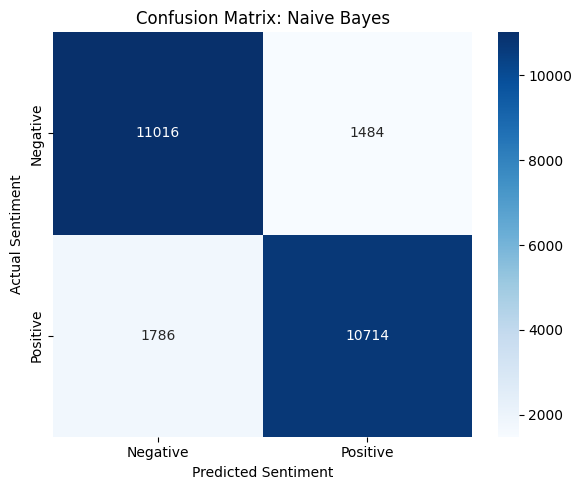

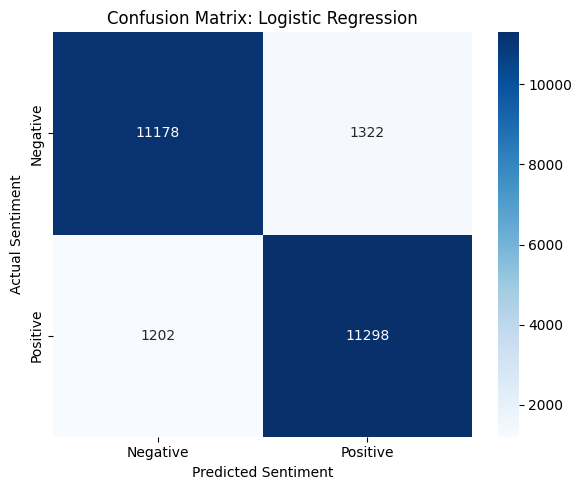

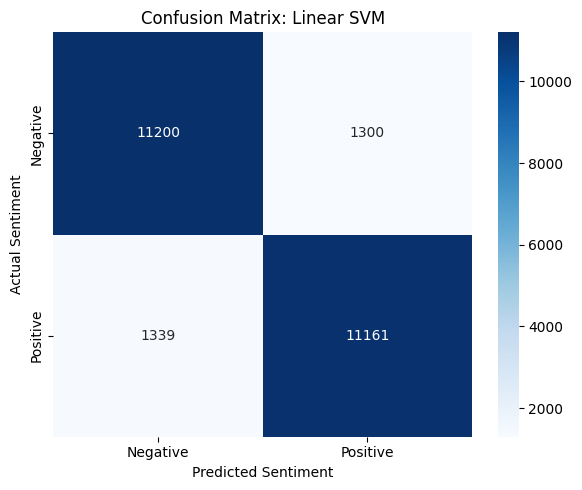

In [9]:
for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")

    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace(" ", "_")
        + "_confusion_matrix.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Custom Testing

In [23]:
custom_review = input("Enter a movie review: ")



# Preprocess
cleaned_review = clean_text(custom_review)

review_tfidf = tfidf.transform([cleaned_review])

sentiment_labels = {
    0: "Negative",
    1: "Positive"
}

# Predictions
custom_predictions = []

for model_name, model in models.items():

    prediction = model.predict(review_tfidf)[0]

    custom_predictions.append({
        "Model": model_name,
        "Predicted Sentiment": sentiment_labels[prediction]
    })



custom_results = pd.DataFrame(custom_predictions)

print("\nCustom Review:")
print(custom_review)

print("\nPredictions:")
display(custom_results)


Custom Review:
this movie made me feel good

Predictions:


,Model,Predicted Sentiment
0,Naive Bayes,Positive
1,Logistic Regression,Positive
2,Linear SVM,Positive
